In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
import fit_lib as fit
import BM29_lib as BM29
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams["text.usetex"] = False
from scipy import optimize
from scipy.optimize import curve_fit
import importlib
import pprint

plt.rcParams['font.size']   = 12

c:\Users\rikoh\Documents\Physik Göttingen&Grenoble 2022-2026\8. SoSe 26\SHK Synaptische Proteine, Lipidmembranen SoSe 2026\Code\BM29_data_and_analysis\analysis_BM29_2026\BM29_lib.py:439: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
  f"$\chi^2_{{\mathrm{{red}}}} = {red_chi2:.3f}$\n"
c:\Users\rikoh\Documents\Physik Göttingen&Grenoble 2022-2026\8. SoSe 26\SHK Synaptische Proteine, Lipidmembranen SoSe 2026\Code\BM29_data_and_analysis\analysis_BM29_2026\BM29_lib.py:439: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  f"$\chi^2_{{\mathrm{{red}}}} = {red_chi2:.3f}$\n"


Computing I(q): 100%|████████████████████████| 908/908 [00:05<00:00, 152.11it/s]


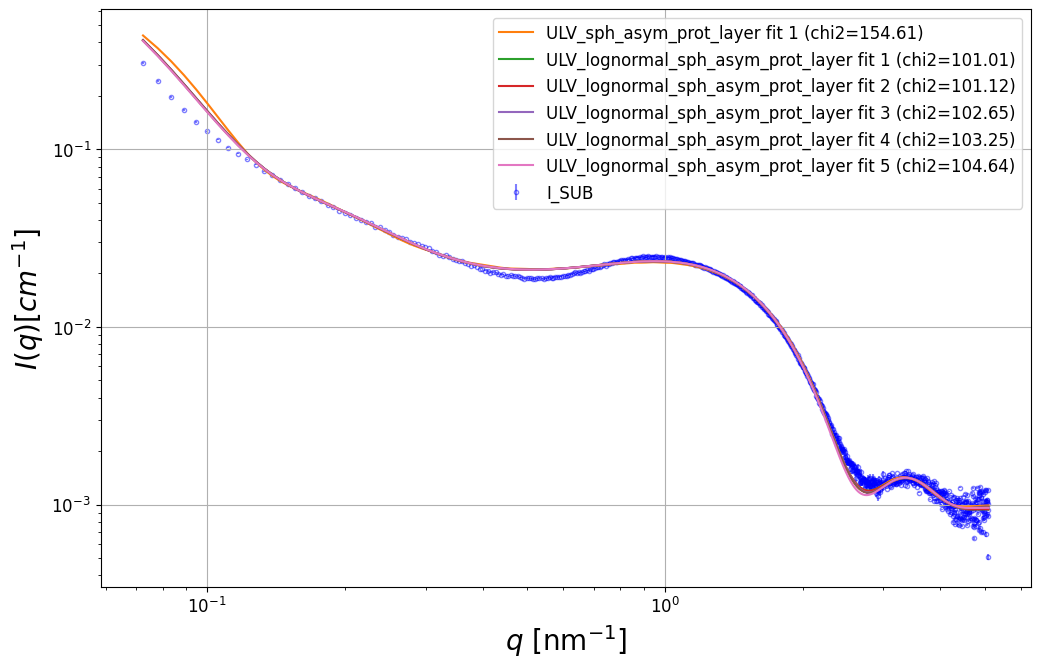

In [2]:
def plot_best_fits(sample, best_fits={"ULV_spheric_asym_C4": [1]}, err_model="Poisson_error_focus_minimum_highq"):

    f=plt.figure(figsize=(12, 7.5))
    block = sample.split("_")[0]
    block_path = BM29.blockpath(block)
    dir_names = [x.name for x in block_path.iterdir()]
    for dir_name in dir_names:
        if dir_name[:-13].endswith(sample):
            sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[sample]
            q, I, Ierr = np.loadtxt(sub_dat_path, unpack=True)

    mask = (q >= 0.07) & (q <= 5.1)
    q    = q[mask]
    I    = I[mask]
    Ierr = Ierr[mask]
    if err_model == "Poisson_error_focus_minimum_highq":
        Ierr_op = BM29.Poisson_error_focus_minimum_highq(q, Ierr)
    plt.errorbar(q, I, Ierr_op, marker="o", markersize=3,markeredgewidth=1,ecolor="Blue",      markeredgecolor='Blue',      markerfacecolor='None', alpha=0.5, ls="None", label='I_SUB', zorder=1)

    for fit_function_name in best_fits.keys():
        for fit_index in best_fits[fit_function_name]:
            popt = BM29.best_fits[sample][fit_function_name][fit_index]
            if fit_function_name == "ULV_spheric_asym_C4_lognormal":
                fit_function = lambda q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale, c4: fit.ULV_spheric_asym_lognormal(q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale,      0, 0, c4)
            elif fit_function_name == "ULV_sph_asym_prot_layer":
                fit_function = lambda q, R, sigma_R, rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h, z_h3, sigma_h3, rho_h3, scale, c4: fit.ULV_sph_asym_prot_layer(q, R, sigma_R, rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h, z_h3, sigma_h3, rho_h3, scale, 0, 0, c4)
            elif fit_function_name == "ULV_spheric_asym_C4":
                fit_function = lambda q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale, c4: fit.ULV_spheric_asym(q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale,      0, 0, c4)
            elif fit_function_name == "ULV_lognormal_sph_asym_prot_layer":
                fit_function = lambda q, R, sigma_R, rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h, z_h3, sigma_h3, rho_h3, scale, c4: fit.ULV_lognormal_sph_asym_prot_layer(q, R, sigma_R, rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h, z_h3, sigma_h3, rho_h3, scale, 0, 0, c4)
            I_fit = fit_function(q, *popt)
            chi2 = BM29.get_chi2(sample, error_model=err_model, p0=popt, fit_function=fit_function_name)
            plt.loglog(q, I_fit, label=f"{fit_function_name} fit {fit_index} (chi2={chi2:.2f})")
    plt.xlabel("$q$ [nm$^{-1}$]", fontsize=20)
    plt.ylabel("$I(q) [cm^{-1}]$", fontsize=20)
    plt.grid()
    # plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
    plt.legend(loc="upper right")
    return f

plt.close("all")
sample = "BVI_S7"
best_fits = {"ULV_sph_asym_prot_layer": [1],"ULV_lognormal_sph_asym_prot_layer": [1,2,3,4,5]}  
f = plot_best_fits(sample, best_fits=best_fits)

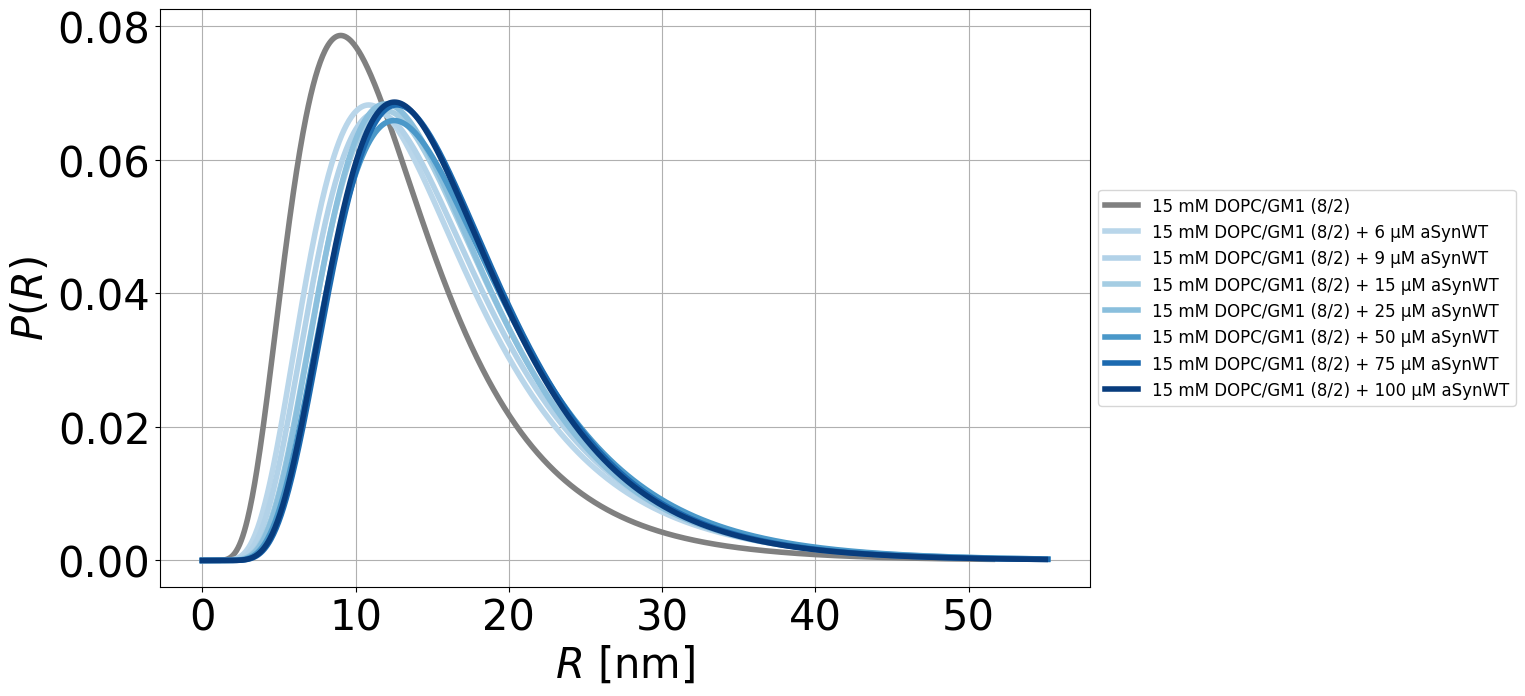

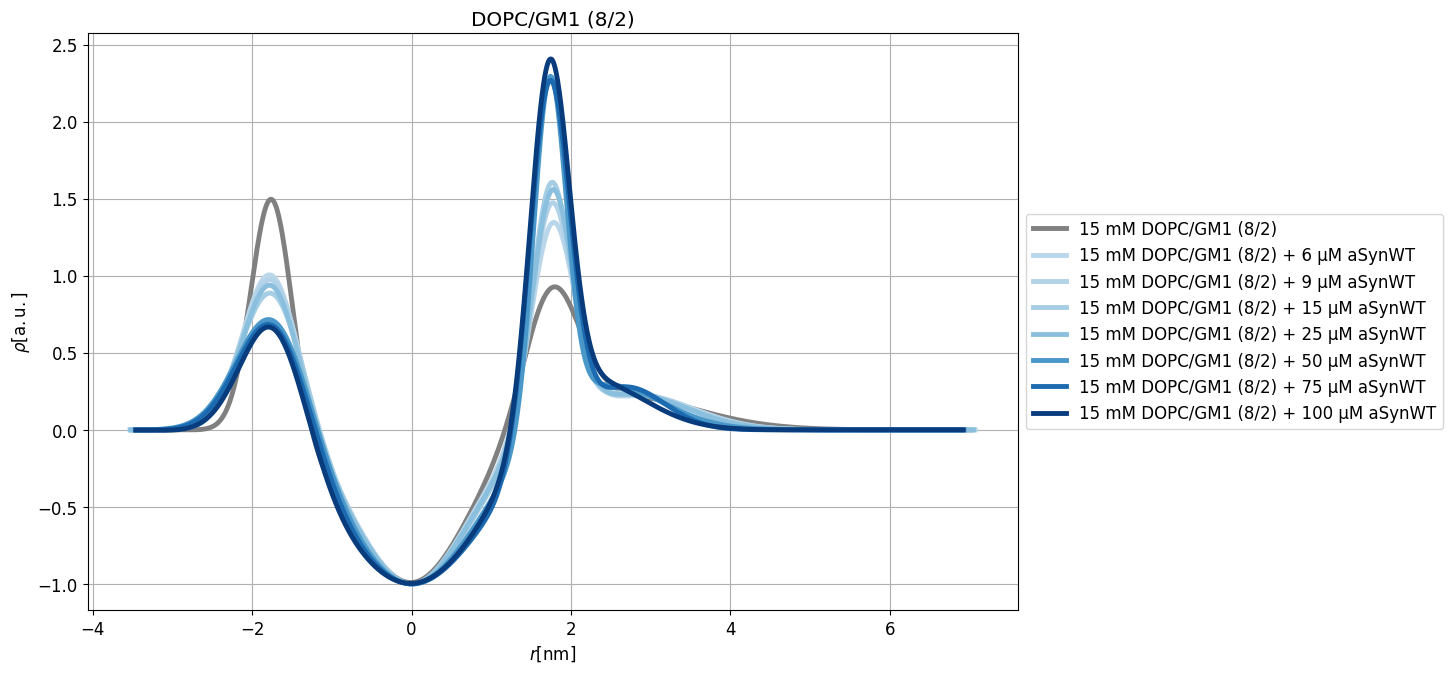

In [2]:
who = ["BIX_S2", "BVI_S1", "BVI_S2", "BVI_S3", "BVI_S4", "BVI_S5", "BVI_S6", "BVI_S7"]
g = BM29.EDP_plot_together(who, title="DOPC/GM1 (8/2)", fit_function="ULV_lognormal_sph_asym_prot_layer")
h = BM29.plot_together_lognorm_polydisp(who, fit_function_name="ULV_lognormal_sph_asym_prot_layer")
plt.show(h)
g

In [ ]:
import ast
from pathlib import Path


def format_best_fits(d, indent=0):
    """Format best_fits with dictionaries nicely indented,
    while keeping parameter lists on a single line."""

    spaces = " " * indent
    lines = ["{"]

    for i, (key, value) in enumerate(d.items()):

        comma = "," if i < len(d) - 1 else ""

        if isinstance(value, dict):

            formatted_value = format_best_fits(value, indent + 4)

            value_lines = formatted_value.splitlines()

            lines.append(
                " " * (indent + 4) + repr(key) + ": " + value_lines[0]
            )

            lines.extend(value_lines[1:])

            lines[-1] += comma

        else:
            # Lists stay entirely on one line
            lines.append(
                " " * (indent + 4)
                + repr(key)
                + ": "
                + repr(value)
                + comma
            )

    lines.append(spaces + "}")

    return "\n".join(lines)


def save_best_fit(sample, model, params, run=1):

    file = Path(BM29.__file__)

    # Read BM29.py
    source = file.read_text()

    # Parse BM29.py
    tree = ast.parse(source)

    # Find best_fits = {...}
    best_fits_node = None

    for node in tree.body:
        if (
            isinstance(node, ast.Assign)
            and any(
                isinstance(target, ast.Name)
                and target.id == "best_fits"
                for target in node.targets
            )
        ):
            best_fits_node = node
            break

    if best_fits_node is None:
        raise RuntimeError(
            "Could not find 'best_fits = ...' in BM29.py"
        )

    # Update dictionary in memory
    BM29.best_fits[sample][model][run] = list(params)

    # Format dictionary
    new_dict = format_best_fits(BM29.best_fits)

    # Split original file into lines
    lines = source.splitlines(keepends=True)

    start = best_fits_node.lineno - 1
    end = best_fits_node.end_lineno

    # Replace ONLY best_fits
    new_source = (
        "".join(lines[:start])
        + "best_fits = "
        + new_dict
        + "\n"
        + "".join(lines[end:])
    )

    # Save BM29.py
    file.write_text(new_source)

    print(f"Saved {sample} / {model} / run {run}")

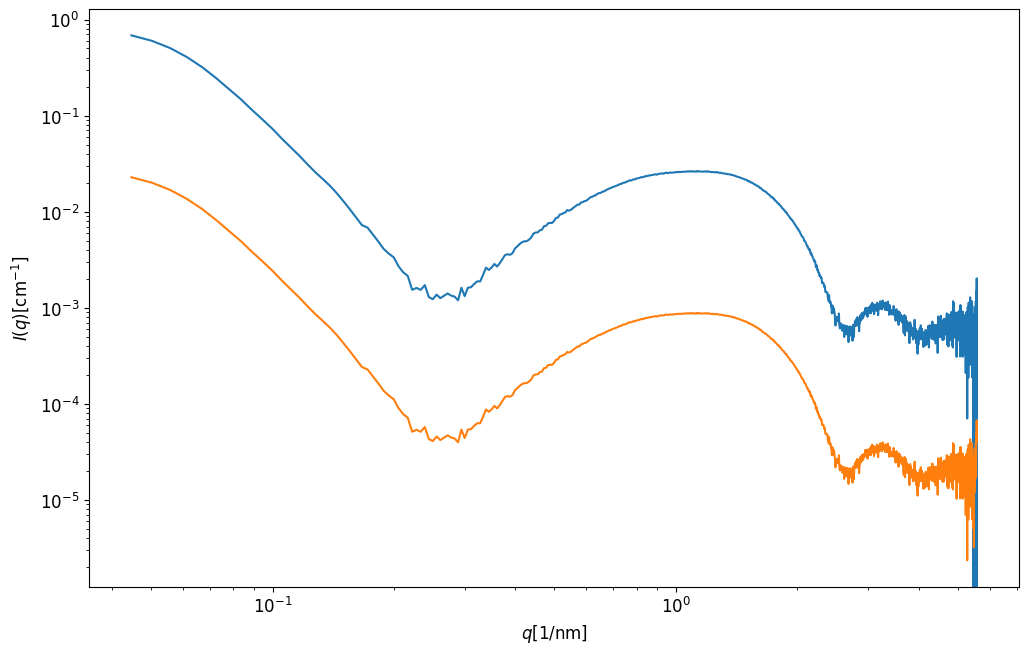

In [ ]:
# EXPLORE ERROR MODELS #############
sample = "BIV_S1" # "BII_S9_15mM_LV4_PBS_FVII"
block = sample.split("_")[0]
block_path = BM29.blockpath(block)
dir_names = [x.name for x in block_path.iterdir()]
for dir_name in dir_names:
    if dir_name[:-13].endswith(sample):
        sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[sample]
        q, I, Ierr = np.loadtxt(sub_dat_path, unpack=True)

Ierr_op1 = BM29.Poisson_error_lowq_highq(q, Ierr)
Ierr_op2 = BM29.op_error_classic(q, I)
Ierr_op3 = BM29.Poisson_error_focus_minimum_highq(q, Ierr)
Ierr_op4 = BM29.Poisson_error_focus_lowq_and_minimum(q, Ierr)

plt.figure(figsize=(12, 7.5))
plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q) [\\mathrm{cm}^{-1}]$')
plt.loglog(q, I, label="SAXS data")
# plt.loglog(q, Ierr, label="Poisson_error")
# plt.loglog(q, Ierr_op1, label="improved_Poisson_error_low_high")
plt.loglog(q, Ierr_op2, label="op_error_classic")
# plt.loglog(q, Ierr_op3, label="op_error_focus_minimum_high")
# plt.loglog(q, Ierr_op4, label="op_error_focus_lowq_and_minimum")
# plt.axvline(x = 0.07, c="black", label="cutoff")
# plt.legend(loc="upper right")

In [ ]:
# CALCULATE CHI2
sample = "BVI_S17" 
block = sample.split("_")[0]
block_path = BM29.blockpath(block)
dir_names = [x.name for x in block_path.iterdir()]
for dir_name in dir_names:
    if dir_name[:-13].endswith(sample):
        print(dir_name)
        sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[sample]
        q, I, Ierr = np.loadtxt(sub_dat_path, unpack=True)

mask = (q >= 0.07) & (q <= 5.1)
q    = q[mask]
I    = I[mask]
Ierr = Ierr[mask]

Ierr_op = BM29.op_error_classic(q, I) #(q, I) #Ierr # BM29.improved_Poisson_error_low_high(q, Ierr)

p0_sph_asym    = BM29.best_fits[sample]["ULV_spheric_asym_C4"][1]
# p0_sph_asym = [15.93, 7.882, 1.046, 2, 0.7708, 0.1788, 0.9389, 1.738, 0.0001255, 0.0004763]
# p0_ellips_asym =  BM29.best_fits[sample]["ULV_sph_asym_prot_layer"][2]
# p0_ellips_asym =  [9.031, 7.667, 1.381, 1.476, 0.4262, 0.4236, 1.172, 1.704, 3.001, 0.712, 0.1976, 4.649e-07, 0.000613]

p0_sph_asym_lognormal = BM29.best_fits[sample]["ULV_spheric_asym_C4_lognormal"][1]
p0_prot_layer = BM29.best_fits[sample]["ULV_sph_asym_prot_layer"][1]

sample_BVI_S170000-subtract


Computing I(q): 100%|████████████████████████| 908/908 [00:01<00:00, 883.25it/s]


For the sample  BVI_S17_15mM_POPG_100uM_aSynWT
chi2 of ULV_spheric_asym_C4:  252.43671447452402
chi2 of sph asym lognormal:  161.959294101479
chi2 of prot layer:  295.4102598960413


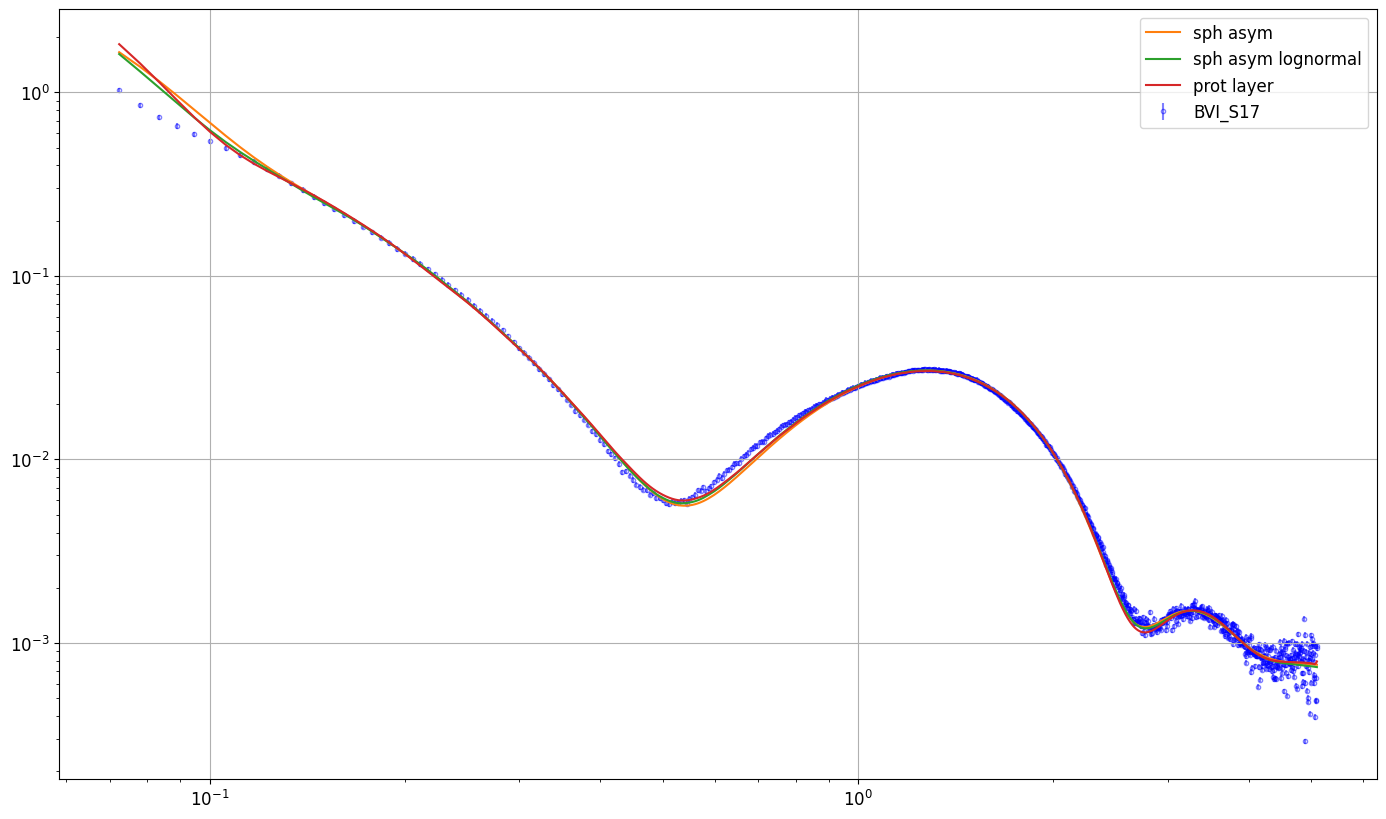

In [ ]:
# p0_ellips_asym = [9.9997, 5.9694, 1.1317, 0.10304, 1.8799, 1.0389, 0.30377, 0.44115, 0.89864, 1.7498, 5.487e-07, 0.0002264] (LV4 pure best fit BM26)

fit_function_name = "ULV_spheric_asym_C4"
fit_function = lambda q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale, c4: fit.ULV_spheric_asym(q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale,      0, 0, c4)
I_sph_asym = fit_function(q, *p0_sph_asym)
chi2_sph_asym = BM29.get_chi2(sample, "Poisson_error_focus_minimum_highq", p0_sph_asym,"ULV_spheric_asym_C4")

# fit_function_name = "ULV_ellipsoid_asym_C4"
# fit_function = lambda q,  R,  sigma_R,     eps, sigma_eps,  rho_h1, rho_h2,   sigma_h1, sigma_h2,  sigma_c,      z_h,    scale, c4: fit.ULV_ellipsoid_asym(q, R,  sigma_R,     eps, sigma_eps,  rho_h1, rho_h2,   sigma_h1, sigma_h2,  sigma_c,      z_h,    scale,   0, 0, c4)
# I_ellips_asym = fit_function(q, *p0_ellips_asym)
# chi2_ellips_asym = BM29.get_chi2(sample, "Poisson_error_focus_minimum_highq", p0_ellips_asym,"ULV_ellipsoid_asym_C4")

fit_function_name = "ULV_sph_asym_prot_layer"
fit_function = lambda q, R, sigma_R, rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h, z_h3, sigma_h3, rho_h3, scale, c4: fit.ULV_sph_asym_prot_layer(q, R, sigma_R, rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h, z_h3, sigma_h3, rho_h3, scale, 0, 0, c4)
I_prot_layer = fit_function(q, *p0_prot_layer)
chi2_prot_layer = BM29.get_chi2(sample, "Poisson_error_focus_minimum_highq", p0_prot_layer,"ULV_sph_asym_prot_layer")

fit_function_name = "ULV_spheric_asym_C4_lognormal"
fit_function = lambda q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale, c4: fit.ULV_spheric_asym_lognormal(q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale,      0, 0, c4)
I_sph_asym_lognormal = fit_function(q, *p0_sph_asym_lognormal)
chi2_sph_asym_lognormal = BM29.get_chi2(sample, "Poisson_error_focus_minimum_highq", p0_sph_asym_lognormal,"ULV_spheric_asym_C4_lognormal")

print("For the sample ", BM29.sample_dict[sample])
print("chi2 of ULV_spheric_asym_C4: ", chi2_sph_asym)
# print("chi2 of ellipsoid_asym_C4: ", chi2_ellips_asym)
print("chi2 of sph asym lognormal: ", chi2_sph_asym_lognormal)
print("chi2 of prot layer: ", chi2_prot_layer)


plt.figure(figsize=(17, 10))
plt.errorbar(q, I, Ierr_op, marker="o", markersize=3,markeredgewidth=1,ecolor="Blue",      markeredgecolor='Blue',      markerfacecolor='None', alpha=0.5, ls="None", label=sample, zorder=1)
plt.loglog(q, I_sph_asym, label="sph asym")
# plt.loglog(q, I_ellips_asym, label="ellips asym")
plt.loglog(q, I_sph_asym_lognormal, label="sph asym lognormal")
plt.loglog(q, I_prot_layer, label="prot layer")
plt.legend()
plt.grid()

In [ ]:
# write params into BM29.best_fits
# importlib.reload(BM29)
# save_best_fit(sample, "ULV_spheric_asym_C4", p0_sph_asym)
# save_best_fit(sample, "ULV_ellipsoid_asym_C4", p0_ellips_asym)



In [ ]:
for sample in BM29.best_fits.keys():
    if (sample.startswith("BVI") or sample.startswith("BVII") or sample.startswith("BIX")):
        print(BM29.sample_dict[sample])
        for fit_function in BM29.best_fits[sample].keys():
                for number in BM29.best_fits[sample][fit_function].keys():
                    p0 = BM29.best_fits[sample][fit_function][number]
                    chi2 = BM29.get_chi2(sample, error_model="Poisson_error_focus_minimum_highq", p0=p0, fit_function=fit_function)
                    print(f"For fit function {fit_function}: number {number}: chi2 = {chi2:.4g}")
        print("\n")
    else:
         continue
    


BVI_S1_15mM_DOPC_GM1_6uM_aSynWT


Computing I(q): 100%|████████████████████████| 908/908 [00:01<00:00, 706.65it/s]


For fit function ULV_sph_asym_prot_layer: number 1: chi2 = 99.05


Computing I(q): 100%|████████████████████████| 908/908 [00:01<00:00, 715.19it/s]


For fit function ULV_sph_asym_prot_layer: number 2: chi2 = 107.7


BVI_S2_15mM_DOPC_GM1_9uM_aSynWT


Computing I(q): 100%|████████████████████████| 908/908 [00:01<00:00, 711.14it/s]


... (133 outputs left out)

Computing I(q): 100%|████████████████████████| 908/908 [00:01<00:00, 618.37it/s]


For fit function ULV_sph_asym_prot_layer: number 2: chi2 = 79.18


BIX_S2_15mM_DOPC_GM1_80_20
For fit function ULV_spheric_asym_C4: number 1: chi2 = 139.7
For fit function ULV_spheric_asym_C4: number 2: chi2 = 140.4
For fit function ULV_spheric_asym_C4: number 3: chi2 = 154.2
For fit function ULV_spheric_asym_C4: number 4: chi2 = 142.4


Computing I(q): 100%|████████████████████████| 908/908 [00:01<00:00, 621.05it/s]

For fit function ULV_sph_asym_prot_layer: number 1: chi2 = 95.19




In [ ]:
who = [
    "BII_S9",

    "BIV_S21",
    "BIV_S22",
    "BIV_S23",
    "BIV_S24",
    "BIV_S25",
    "BIV_S26",
    "BIV_S27",
    "BIV_S28",
    "BIV_S29",
    "BIV_S30"
]

for sample in who:
    R_spheric = BM29.best_fits[sample]["ULV_spheric_asym_C4"][1][0]
    R_ellips  = BM29.best_fits[sample]["ULV_ellipsoid_asym_C4"][1][0]
    Rmean = np.mean([R_spheric, R_ellips])
    Rstd = np.std([R_spheric, R_ellips])
    print(f"{sample} has R_mean = {Rmean:.4g} +- {Rstd:.4g} nm")

who = [
    "BII_S9",

    "BIV_S1",
    "BIV_S2",
    "BIV_S3",
    "BIV_S4",
    "BIV_S5",
    "BIV_S6",
    "BIV_S7",
    "BIV_S8",
    "BIV_S9",
    "BIV_S10",
]

for sample in who:
    R_spheric = BM29.best_fits[sample]["ULV_spheric_asym_C4"][1][0]
    R_ellips  = BM29.best_fits[sample]["ULV_ellipsoid_asym_C4"][1][0]
    Rmean = np.mean([R_spheric, R_ellips])
    Rstd = np.std([R_spheric, R_ellips])
    print(f"{sample} has R_mean = {Rmean:.4g} +- {Rstd:.4g} nm")

BII_S9 has R_mean = 15.99 +- 0.1 nm


KeyError: 1

Computing I(q): 100%|████████████████████████| 908/908 [00:05<00:00, 172.08it/s]


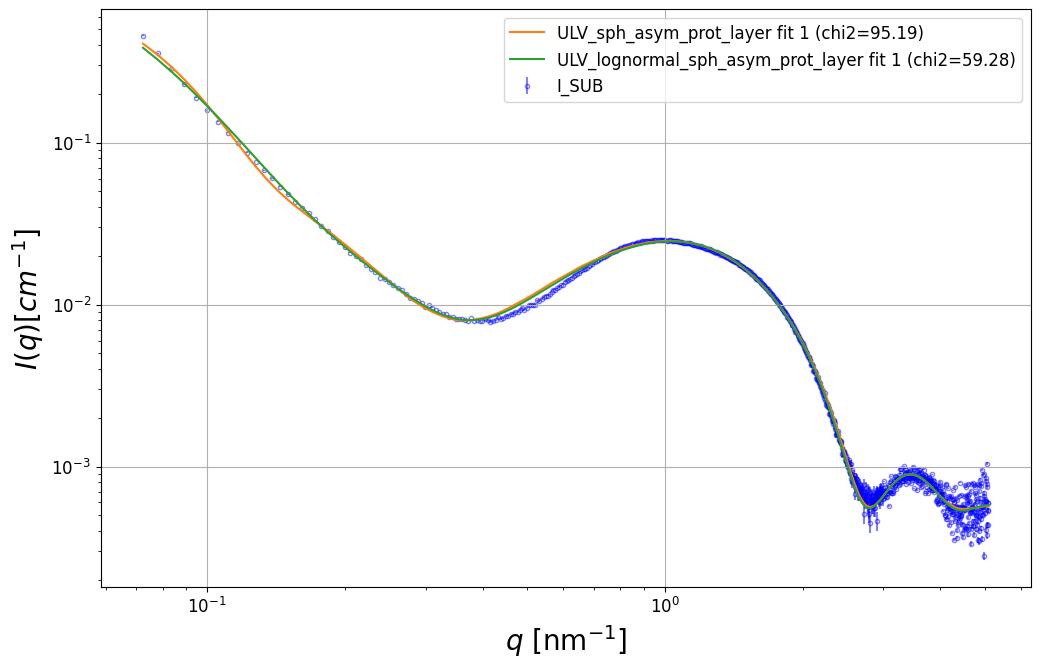